# Задача 5

Построить интерполяционный полином $P_n(x)$ для функции $J_0(x)$
в промежутке $[0,10]$, используя равномерную сетку.
Нарисовать графики $P_n(x)-J_0(x)$ для разного числа узлов интерполяции.
Объяснить результат.

---

## Равномерная сетка и полином Лагранжа.

Возьмём $n+1$ узел на отрезке $[a,b]=[0,10]$:

$$
    x_i=a+ih, \qquad h=\frac{b-a}{n}, \qquad i=0,\ldots,n,
    \qquad y_i=J_0(x_i).
$$

Здесь $n$ — степень полинома (не выше $n$), а число узлов равно $n+1$.
Как в лекции, используем форму Лагранжа:

$$
    P_n(x)=\sum_{i=0}^{n}y_i L_i(x), \qquad
    L_i(x)=\prod_{\substack{j=0\\j\ne i}}^n
    \frac{x-x_j}{x_i-x_j}.
$$

В узле $x_k$ имеем $L_i(x_k)=\delta_{ik}$, поэтому $P_n(x_k)=y_k$.
Все узлы различны, следовательно, такой полином существует и единственен.
Реализуем формулу напрямую, не решая систему Вандермонда.

## Значения функции Бесселя.

Как в задаче 4, вычислим функцию через интегральное представление:

$$
    J_0(x)=\frac1\pi\int_0^\pi\cos(x\sin t)\,dt.
$$

Используем формулу Симпсона с серединой каждого из $N$ интервалов.
Параметр $N$ относится к **интегрированию**, а $n$ — к **интерполяции**.
Для контроля сравним интегралы при $N$ и $2N$ на всём отрезке $[0,10]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a = 0.0
b = 10.0
N_integral = 64
n_values = [4, 8, 12, 16, 20]
M = 4000


def find_j0(x, N=64):
    x = np.asarray(x, dtype=float)
    dt = np.pi / N
    total = np.zeros_like(x)
    for i in range(N):
        left = i * dt
        right = (i + 1) * dt
        middle = (left + right) / 2
        total += (np.cos(x * np.sin(left))
                  + 4 * np.cos(x * np.sin(middle))
                  + np.cos(x * np.sin(right)))
    return dt * total / (6 * np.pi)


x_grid = np.linspace(a, b, M + 1)
j0_grid = find_j0(x_grid, N_integral)
integral_change = np.max(np.abs(find_j0(x_grid, 2*N_integral) - j0_grid))
print(f"J0(0) = {float(find_j0(0, N_integral)):.15f}")
print(f"max |J0(2N) - J0(N)| на {M+1} точках: {integral_change:.3e}")

J0(0) = 1.000000000000000
max |J0(2N) - J0(N)| на 4001 точках: 1.110e-15


## Построение интерполяционного полинома.

Функция ниже получает точки, в которых нужно вычислить полином,
и массивы узлов и значений. Для каждого $i$ последовательно перемножаем
множители $L_i(x)$ и прибавляем слагаемое $y_iL_i(x)$.

In [2]:
def find_lagrange(x, x_nodes, y_nodes):
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    for i in range(len(x_nodes)):
        basis = np.ones_like(x)
        for j in range(len(x_nodes)):
            if j != i:
                basis *= (x - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        result += y_nodes[i] * basis
    return result

### Проверка в узлах и между ними:

Для каждого $n$ построим новый полином по равномерной сетке.
Проверим условие интерполяции и оценим максимальную абсолютную ошибку
на отдельной подробной сетке из $4001$ точки:

$$
    E_n=\max_{0\le k\le M}|P_n(\widehat x_k)-J_0(\widehat x_k)|,
    \qquad \widehat x_k=a+k\frac{b-a}{M}.
$$

Это максимум на контрольной сетке; он приближает максимум на всём отрезке.

In [3]:
results = {}
print(f"{'n':>4} {'Узлов':>7} {'h':>10} {'Ошибка в узлах':>18} {'E_n':>14} {'x максимума':>14}")
for n in n_values:
    x_nodes = np.linspace(a, b, n + 1)
    y_nodes = find_j0(x_nodes, N_integral)
    polynomial = find_lagrange(x_grid, x_nodes, y_nodes)
    error = polynomial - j0_grid
    node_error = np.max(np.abs(find_lagrange(x_nodes, x_nodes, y_nodes) - y_nodes))
    index = np.argmax(np.abs(error))
    results[n] = dict(x_nodes=x_nodes, y_nodes=y_nodes,
                      polynomial=polynomial, error=error)
    print(f"{n:4d} {n+1:7d} {(b-a)/n:10.5f} {node_error:18.3e} "
          f"{abs(error[index]):14.5e} {x_grid[index]:14.5f}")
    assert node_error < 1e-12

   n   Узлов          h     Ошибка в узлах            E_n    x максимума
   4       5    2.50000          0.000e+00    3.11166e-01        8.99500
   8       9    1.25000          0.000e+00    1.42820e-02        0.38500
  12      13    0.83333          0.000e+00    1.16713e-04        0.23000
  16      17    0.62500          0.000e+00    2.93078e-07        0.16000
  20      21    0.50000          0.000e+00    3.01723e-10        0.12250


## Графики функции и полиномов.

На первом рисунке сравним $J_0(x)$ и несколько полиномов.
Точки показывают узлы, по которым строился соответствующий полином.

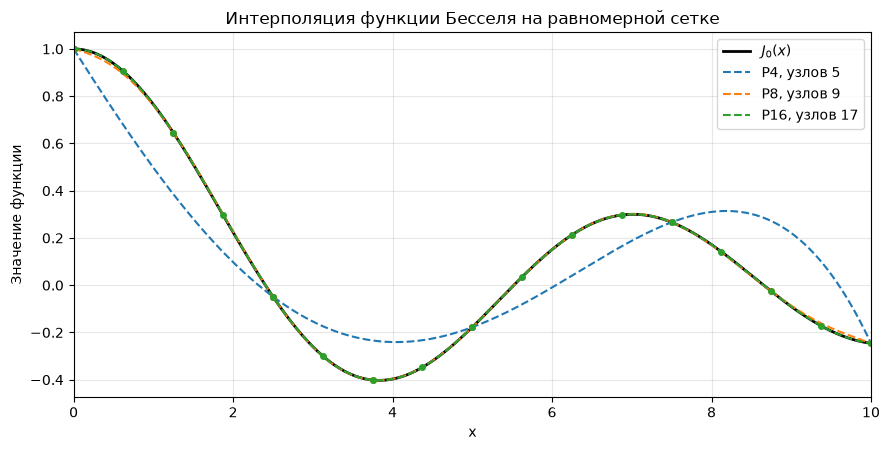

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(x_grid, j0_grid, "k-", linewidth=2, label=r"$J_0(x)$")
for n in [4, 8, 16]:
    line, = ax.plot(x_grid, results[n]["polynomial"], "--", label=f"P{n}, узлов {n+1}")
    ax.plot(results[n]["x_nodes"], results[n]["y_nodes"], "o",
            color=line.get_color(), markersize=4)
ax.set(xlim=(a, b), xlabel="x", ylabel="Значение функции",
       title="Интерполяция функции Бесселя на равномерной сетке")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Графики разности $P_n(x)-J_0(x)$.

Масштаб по вертикали у каждого графика свой: иначе малые ошибки
полиномов более высокой степени были бы не видны.
Во всех узлах интерполяции разность обращается в нуль с точностью вычислений.

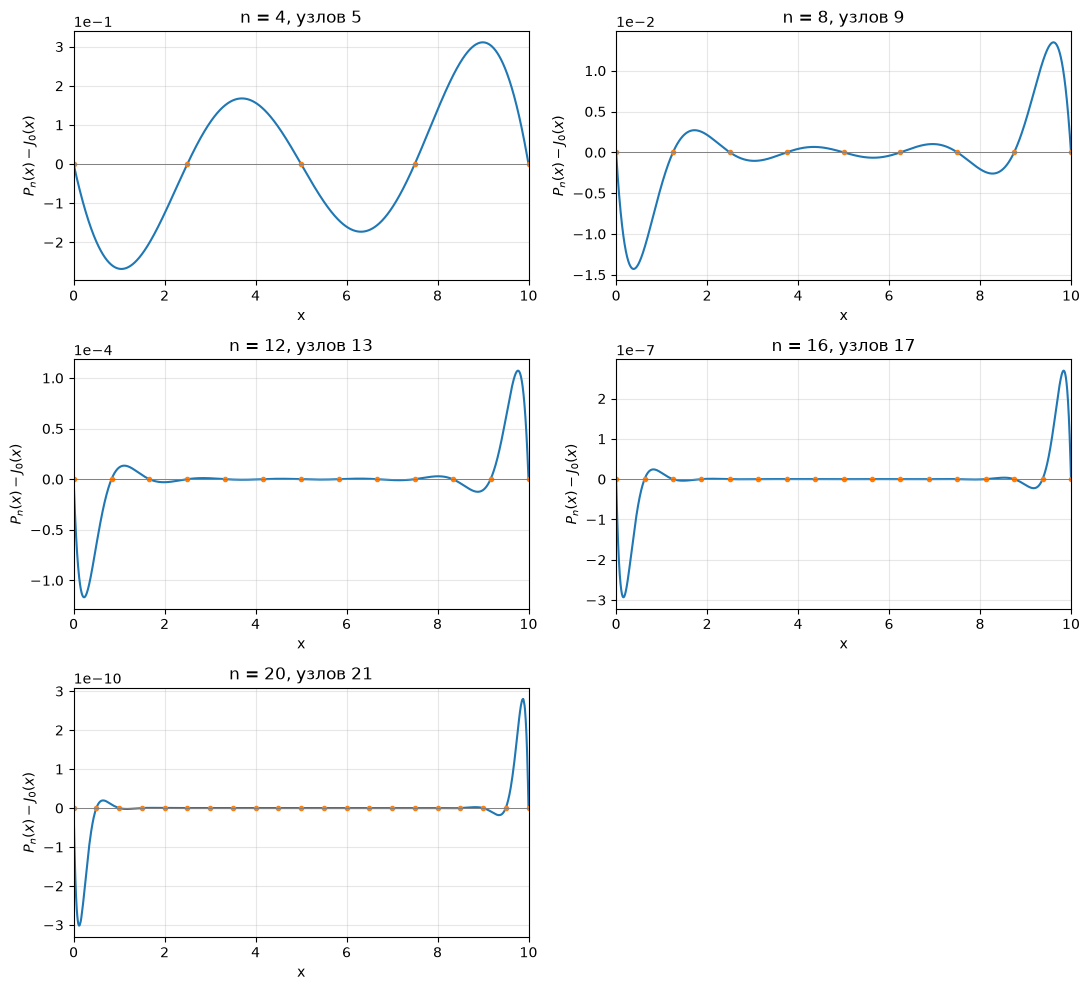

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, n in zip(axes.flat, n_values):
    ax.plot(x_grid, results[n]["error"])
    ax.plot(results[n]["x_nodes"], np.zeros(n+1), "o", markersize=3)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlim=(a, b), xlabel="x", ylabel=r"$P_n(x)-J_0(x)$",
           title=f"n = {n}, узлов {n+1}")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(True, alpha=0.3)
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

## Объяснение результата.

Для гладкой функции остаток интерполяции имеет вид

$$
    J_0(x)-P_n(x)=\frac{J_0^{(n+1)}(\xi_x)}{(n+1)!}
    \prod_{i=0}^{n}(x-x_i), \qquad \xi_x\in[0,10].
$$

Произведение равно нулю в узлах и меняет знак между соседними узлами.
Поэтому на графиках видны колебания разности, а между узлами ошибка
может быть существенно больше, чем в самих узлах.

Из интегрального представления, дифференцируя под знаком интеграла,
получаем для любого целого $k\ge0$ и вещественного $x$

$$
    |J_0^{(k)}(x)|\le\frac1\pi\int_0^\pi|\sin t|^k\,dt\le1.
$$

Поскольку $|x-x_i|\le10$, справедлива грубая, но достаточная оценка

$$
    \max_{[0,10]}|J_0(x)-P_n(x)|
    \le\frac{10^{n+1}}{(n+1)!}\longrightarrow0.
$$

Таким образом, **в точной арифметике интерполяция этой функции сходится**
и на равномерной сетке. Нельзя автоматически объяснять любые колебания
расходимостью Рунге: здесь для этого нет оснований.

В машинной арифметике к остатку интерполяции добавляются ошибки
вычисления $J_0$ и самого полинома. Погрешности $\delta y_i$ в узлах
дают возмущение

$$
    |\delta P_n(x)|\le\max_i|\delta y_i|\sum_{i=0}^{n}|L_i(x)|.
$$

Сумма модулей базисных полиномов может быстро расти на равномерной сетке,
особенно у краёв. Поэтому при больших $n$ уменьшение математического
остатка перестаёт улучшать вычисленный результат.

   n   Узлов      max |Pn - J0|
   4       5        3.11166e-01
   8       9        1.42820e-02
  12      13        1.16713e-04
  16      17        2.93078e-07
  20      21        3.01723e-10
  24      25        8.42848e-12
  28      29        1.26706e-10
  32      33        1.90979e-09
  36      37        3.00673e-08
  40      41        3.82106e-07


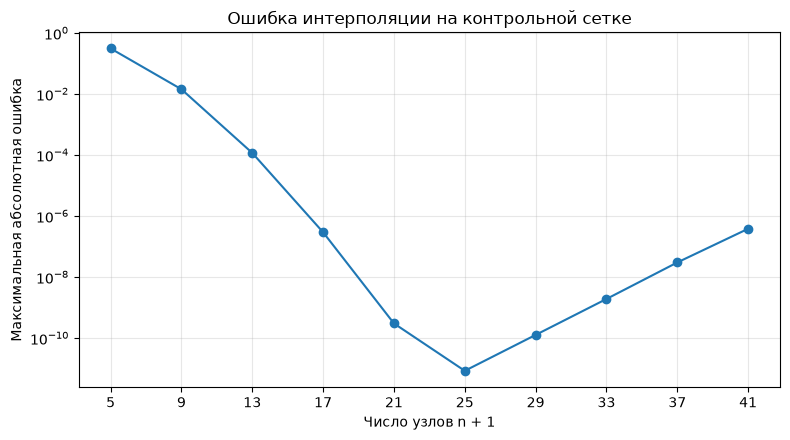

In [6]:
n_scan = np.array([4, 8, 12, 16, 20, 24, 28, 32, 36, 40])
max_errors = []
print(f"{'n':>4} {'Узлов':>7} {'max |Pn - J0|':>18}")
for n in n_scan:
    x_nodes = np.linspace(a, b, n + 1)
    y_nodes = find_j0(x_nodes, N_integral)
    error = np.max(np.abs(find_lagrange(x_grid, x_nodes, y_nodes) - j0_grid))
    max_errors.append(error)
    print(f"{n:4d} {n+1:7d} {error:18.5e}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(n_scan + 1, max_errors, "o-")
ax.set(xlabel="Число узлов n + 1", ylabel="Максимальная абсолютная ошибка",
       title="Ошибка интерполяции на контрольной сетке")
ax.set_xticks(n_scan + 1)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## Ответ.

Искомый полином построен по формуле

$$
    \boxed{P_n(x)=\sum_{i=0}^{n}J_0\!\left(\frac{10i}{n}\right)
    \prod_{\substack{j=0\\j\ne i}}^{n}
    \frac{x-10j/n}{10i/n-10j/n}}.
$$

Графики разности приведены для $5,9,13,17,21$ узла.
С увеличением числа узлов ошибка сначала быстро убывает, затем при
высоких степенях становится заметно влияние округления.
Равенство в узлах само по себе не гарантирует малую ошибку между ними.
Для $J_0$ на $[0,10]$ теоретическая сходимость следует из оценки остатка,
а рост вычисленной ошибки при больших $n$ связан с машинной арифметикой.